# Evaluación Formativa 2: Validación, simulación y remuestreo
## Dataset: *Rain in Australia* (weatherAUS)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello

**Grupo 4:** Jeremmy Díaz Alfaro · Karim Zaid Sánchez · Laura Arenas Kosin

En este notebook tomamos los resultados de la **Sumativa 1** (`01_formativa1_eda.ipynb`) y los ponemos a prueba con métodos computacionales:

1. **Bootstrap** (percentil y BCa) sobre los parámetros estimados en la S1 (ID2.1)
2. **Test de permutación** sobre dos pruebas de hipótesis de la S1 (ID2.1)
3. **Estabilidad de correlaciones** con intervalos bootstrap (ID2.1)
4. **Simulación Monte Carlo** con parámetros de la S1, que genera datos sintéticos (ID2.2)
5. **Análisis de robustez** frente a valores extremos y supuestos (ID2.3)
6. **Reporte de resultados validados** para la Sumativa 3

Cada sección reinicia la semilla en `42`, así que el notebook se puede ejecutar completo o celda por celda y da los mismos resultados.

## 0. Configuración y datos

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

raiz = Path.cwd().resolve()
while not (raiz / "src").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.append(str(raiz))
from src.carga_datos import cargar_weather

SEED = 42
FIGURAS = raiz / "figuras"
FIGURAS.mkdir(exist_ok=True)
PROCESADOS = raiz / "data" / "processed"
PROCESADOS.mkdir(parents=True, exist_ok=True)

# misma paleta de la Sumativa 1
INK = '#2b2b2b'; TEAL = '#2e6b75'; TERRA = '#a35140'; OCHRE = '#c4862f'; STEM = '#bdb3a3'
BG = '#f6f1ea'; GRID = '#ddd5c6'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.family': 'serif', 'font.size': 10,
    'axes.facecolor': BG, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

z = stats.norm.ppf(0.975)
TARGET = 'RainTomorrow'

# misma limpieza básica de la S1: la nubosidad 9 no es válida en octas
df = cargar_weather()
for c in ['Cloud9am', 'Cloud3pm']:
    df.loc[df[c] > 8, c] = np.nan
df_obj = df.dropna(subset=[TARGET]).copy()
df_obj['y'] = (df_obj[TARGET] == 'Yes').astype(int)
print(f"Filas: {len(df):,} | con objetivo: {len(df_obj):,}")

Filas: 145,460 | con objetivo: 142,193


### Resultados de la Sumativa 1 que vamos a validar

En la S1 (Tabla 2) estimamos con intervalo clásico al 95 % la media de la temperatura máxima, de la lluvia diaria y de la humedad a las 3 pm, y la proporción de días con lluvia al día siguiente. También hicimos tres pruebas de hipótesis (*t* de Welch para la humedad, χ² para la nubosidad y *z* para "¿llovió hoy?") y describimos las correlaciones entre variables. Abajo recalculamos los intervalos clásicos para usarlos como referencia.

In [2]:
def ic_clasico(x):
    x = pd.Series(x).dropna().to_numpy(dtype=float)
    m = x.mean()
    se = x.std(ddof=1) / np.sqrt(len(x))
    return m, m - z * se, m + z * se, len(x)

PARAMS = [
    ('MaxTemp', 'Temperatura máxima media (°C)', df['MaxTemp']),
    ('Rainfall', 'Lluvia diaria media (mm)', df['Rainfall']),
    ('Humidity3pm', 'Humedad media a las 3 pm (%)', df['Humidity3pm']),
    ('p_lluvia', 'Proporción de días con lluvia mañana', df_obj['y']),
]
S1 = {}
for clave, nombre, x in PARAMS:
    S1[clave] = ic_clasico(x)
    m, lo, hi, nn = S1[clave]
    print(f"{nombre:38s} {m:9.4f}   IC clásico [{lo:.4f}; {hi:.4f}]   n={nn:,}")

Temperatura máxima media (°C)            23.2213   IC clásico [23.1846; 23.2581]   n=144,199
Lluvia diaria media (mm)                  2.3609   IC clásico [2.3169; 2.4050]   n=142,199
Humedad media a las 3 pm (%)             51.5391   IC clásico [51.4306; 51.6477]   n=140,953
Proporción de días con lluvia mañana      0.2242   IC clásico [0.2220; 0.2263]   n=142,193


---
## 1. Validación con bootstrap: percentil y BCa frente al IC clásico

**Idea del bootstrap:** como no conocemos la población, usamos la muestra como si lo fuera. Sacamos 10.000 remuestras del mismo tamaño **con reemplazo**, calculamos la media en cada una y miramos cuánto varía.

- **Intervalo percentil:** se queda con el 2,5 % y el 97,5 % de las 10.000 medias. Supone que esa distribución está centrada y es simétrica.
- **Intervalo BCa:** corrige el percentil con dos factores: el **sesgo** (z0, si la distribución bootstrap está corrida respecto de la estimación) y la **aceleración** (a, que mide la asimetría y se calcula con jackknife). Si z0 y a son casi 0, el BCa queda igual al percentil.
- **Intervalo clásico (S1):** supone que la media muestral es aproximadamente normal (Teorema Central del Límite).

In [3]:
rng = np.random.default_rng(SEED)   # sección reproducible
B = 10_000

def boot_media(x, B=B, lote=100):
    """Bootstrap no paramétrico de la media: B remuestras con reemplazo (en lotes para no llenar la memoria)."""
    x = pd.Series(x).dropna().to_numpy(dtype=float)
    n = len(x)
    reps = np.empty(B)
    hechas = 0
    while hechas < B:
        b = min(lote, B - hechas)
        idx = rng.integers(0, n, size=(b, n))
        reps[hechas:hechas + b] = x[idx].mean(axis=1)
        hechas += b
    return x, reps

def ic_bca(x, reps, theta, alpha=0.05):
    """Intervalo BCa: corrige el sesgo (z0) y la asimetría o aceleración (a, con jackknife)."""
    z0 = stats.norm.ppf(np.mean(reps < theta))
    n = len(x)
    jack = (x.sum() - x) / (n - 1)          # media jackknife dejando fuera cada observación
    d = jack.mean() - jack
    a = (d ** 3).sum() / (6 * ((d ** 2).sum()) ** 1.5)
    zl, zu = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    a1 = stats.norm.cdf(z0 + (z0 + zl) / (1 - a * (z0 + zl)))
    a2 = stats.norm.cdf(z0 + (z0 + zu) / (1 - a * (z0 + zu)))
    return np.percentile(reps, 100 * a1), np.percentile(reps, 100 * a2), z0, a

boot = {}
filas = []
for clave, nombre, x in PARAMS:
    m, clo, chi, nn = S1[clave]
    xv, reps = boot_media(x)
    plo, phi = np.percentile(reps, [2.5, 97.5])
    blo, bhi, z0, a = ic_bca(xv, reps, m)
    boot[clave] = dict(reps=reps, m=m, clasico=(clo, chi), percentil=(plo, phi), bca=(blo, bhi), nombre=nombre)
    filas.append([nombre, m, f"[{clo:.4f}; {chi:.4f}]", f"[{plo:.4f}; {phi:.4f}]",
                  f"[{blo:.4f}; {bhi:.4f}]", round(z0, 3), round(a, 4)])

tabla1 = pd.DataFrame(filas, columns=['Parámetro', 'Estimación', 'IC clásico (S1)', 'IC percentil',
                                      'IC BCa', 'z0', 'a']).set_index('Parámetro')
tabla1

,Estimación,IC clásico (S1),IC percentil,IC BCa,z0,a
Parámetro,,,,,,
Temperatura máxima media (°C),23.221348,[23.1846; 23.2581],[23.1850; 23.2583],[23.1851; 23.2584],0.002,0.0001
Lluvia diaria media (mm),2.360918,[2.3169; 2.4050],[2.3169; 2.4050],[2.3173; 2.4053],-0.001,0.0043
Humedad media a las 3 pm (%),51.539116,[51.4306; 51.6477],[51.4311; 51.6448],[51.4309; 51.6446],-0.003,0.0000
Proporción de días con lluvia mañana,0.224181,[0.2220; 0.2263],[0.2220; 0.2263],[0.2220; 0.2263],-0.010,0.0006


**Tabla 1.** Intervalos de confianza al 95 %: clásico de la S1, percentil y BCa (10.000 remuestras).

### Figura 1 - Distribuciones bootstrap y comparación de intervalos

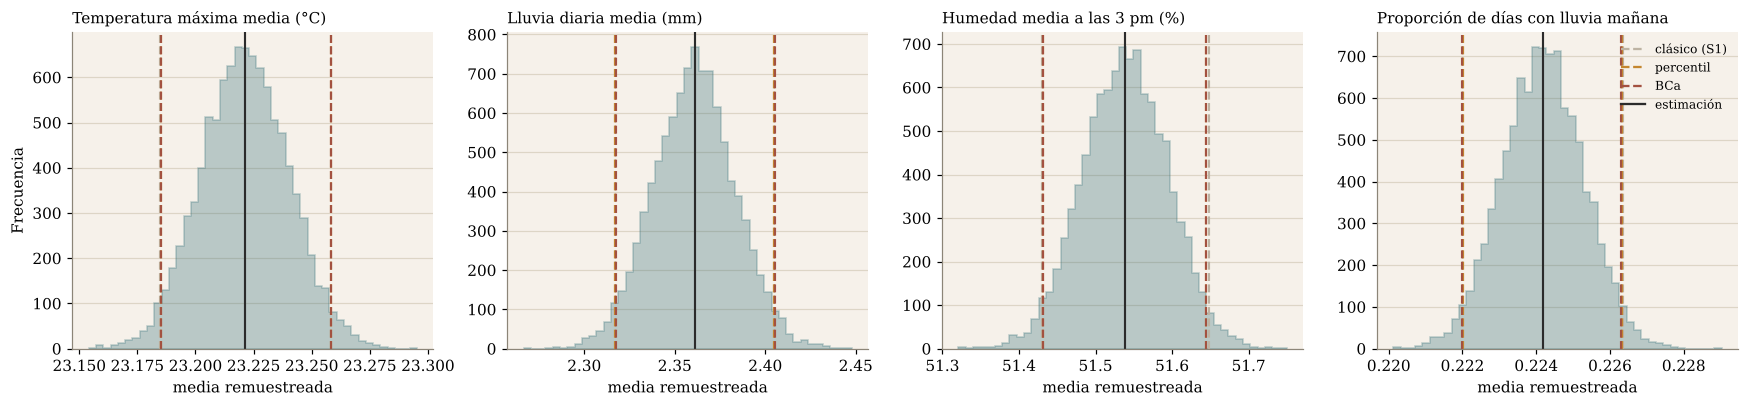

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (clave, _, _) in zip(axes, PARAMS):
    b = boot[clave]
    ax.hist(b['reps'], bins=45, histtype='stepfilled', color=TEAL, alpha=0.30, edgecolor=TEAL, linewidth=1.0)
    for (lo, hi), col in [(b['clasico'], STEM), (b['percentil'], OCHRE), (b['bca'], TERRA)]:
        ax.axvline(lo, color=col, lw=1.4, ls='--'); ax.axvline(hi, color=col, lw=1.4, ls='--')
    ax.axvline(b['m'], color=INK, lw=1.4)
    ax.set_title(b['nombre'], fontsize=10)
    ax.set_xlabel('media remuestreada')
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Frecuencia')
leyenda = [Line2D([0], [0], color=STEM, ls='--', label='clásico (S1)'),
           Line2D([0], [0], color=OCHRE, ls='--', label='percentil'),
           Line2D([0], [0], color=TERRA, ls='--', label='BCa'),
           Line2D([0], [0], color=INK, label='estimación')]
axes[3].legend(handles=leyenda, fontsize=8, frameon=False, loc='upper right')
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_bootstrap.png', bbox_inches='tight')
plt.show()

**Lectura.** En los cuatro parámetros los tres intervalos prácticamente coinciden (las líneas se tapan unas con otras en la figura). Los factores de corrección del BCa son casi cero: z0 está entre −0,01 y 0,002, y a es como máximo 0,004. El caso con más corrección es la **lluvia diaria**, la variable más asimétrica (a = 0,004), pero aun así el BCa se mueve menos de una milésima de mm respecto del clásico.

¿Por qué coinciden si la lluvia es tan asimétrica? Porque tenemos más de 140.000 días: con ese tamaño, la **media muestral** sí se distribuye casi normal aunque la variable no lo sea (Teorema Central del Límite), y eso se ve en los histogramas, que son simétricos. Conclusión: los intervalos clásicos que reportamos en la S1 son confiables. Ojo que esto no dice que la media de la lluvia sea un buen resumen de un día típico; eso lo revisamos en la sección 5.

---
## 2. Validación de pruebas de hipótesis con permutación

**Idea:** si H0 es cierta (no hay relación con la lluvia de mañana), da lo mismo qué días tienen la etiqueta "llueve mañana". Entonces mezclamos las etiquetas al azar 10.000 veces, recalculamos el estadístico cada vez y vemos qué tan raro es el valor que observamos de verdad. El valor p es la proporción de permutaciones que igualan o superan el observado. Esta prueba **no supone normalidad**.

### 2.1 *t* de Welch de la S1: humedad a las 3 pm según si llueve mañana

In [5]:
rng = np.random.default_rng(SEED)   # sección reproducible
h = df_obj[['Humidity3pm', 'y']].dropna()
hum = h['Humidity3pm'].to_numpy(dtype=float)
lab = h['y'].to_numpy()
n, n1 = len(hum), int(lab.sum())
n0 = n - n1
total = hum.sum()

obs_t = hum[lab == 1].mean() - hum[lab == 0].mean()
t_welch, p_welch = stats.ttest_ind(hum[lab == 1], hum[lab == 0], equal_var=False)

B_perm = 10_000
perm_t = np.empty(B_perm)
for j in range(B_perm):
    idx = rng.choice(n, size=n1, replace=False)   # etiquetas "lluvia mañana" al azar
    s1 = hum[idx].sum()
    perm_t[j] = s1 / n1 - (total - s1) / n0

p_perm_t = (np.sum(np.abs(perm_t) >= abs(obs_t)) + 1) / (B_perm + 1)
print(f"Diferencia observada (lluvia - sin lluvia) = {obs_t:.2f} puntos de humedad")
print(f"Distribución nula: rango [{perm_t.min():.3f}; {perm_t.max():.3f}], desv. est. = {perm_t.std():.3f}")
print(f"Valor p de permutación = {p_perm_t:.5f}   (Welch de la S1: t = {t_welch:.1f}, p < 0,0001)")

Diferencia observada (lluvia - sin lluvia) = 22.29 puntos de humedad
Distribución nula: rango [-0.484; 0.478], desv. est. = 0.134
Valor p de permutación = 0.00010   (Welch de la S1: t = 182.6, p < 0,0001)


### 2.2 χ² de la S1: nubosidad a las 3 pm (tres tramos) y lluvia mañana

In [6]:
rng = np.random.default_rng(SEED)   # sección reproducible
c = df_obj[['Cloud3pm', 'y']].dropna()
tramo = pd.cut(c['Cloud3pm'], bins=[-1, 2, 5, 8], labels=False).to_numpy()   # 0 despejado, 1 parcial, 2 cubierto
yc = c['y'].to_numpy()

def chi2_stat(tramo, y):
    obs = np.bincount(tramo * 2 + y, minlength=6).reshape(3, 2)
    esp = obs.sum(axis=1, keepdims=True) * obs.sum(axis=0, keepdims=True) / obs.sum()
    return ((obs - esp) ** 2 / esp).sum()

obs_chi = chi2_stat(tramo, yc)
p_chi_param = stats.chi2.sf(obs_chi, df=2)
perm_chi = np.array([chi2_stat(tramo, rng.permutation(yc)) for _ in range(B_perm)])
p_perm_chi = (np.sum(perm_chi >= obs_chi) + 1) / (B_perm + 1)
print(f"Chi² observado = {obs_chi:,.1f}  (n = {len(yc):,})")
print(f"Chi² bajo H0 (permutaciones): máximo = {perm_chi.max():.1f}, percentil 95 = {np.percentile(perm_chi, 95):.2f}")
print(f"Valor p de permutación = {p_perm_chi:.5f}   (paramétrico de la S1: p < 0,0001)")

Chi² observado = 10,812.6  (n = 85,098)
Chi² bajo H0 (permutaciones): máximo = 18.0, percentil 95 = 5.89
Valor p de permutación = 0.00010   (paramétrico de la S1: p < 0,0001)


### Figura 2 - Distribuciones bajo H0 (10.000 permutaciones)

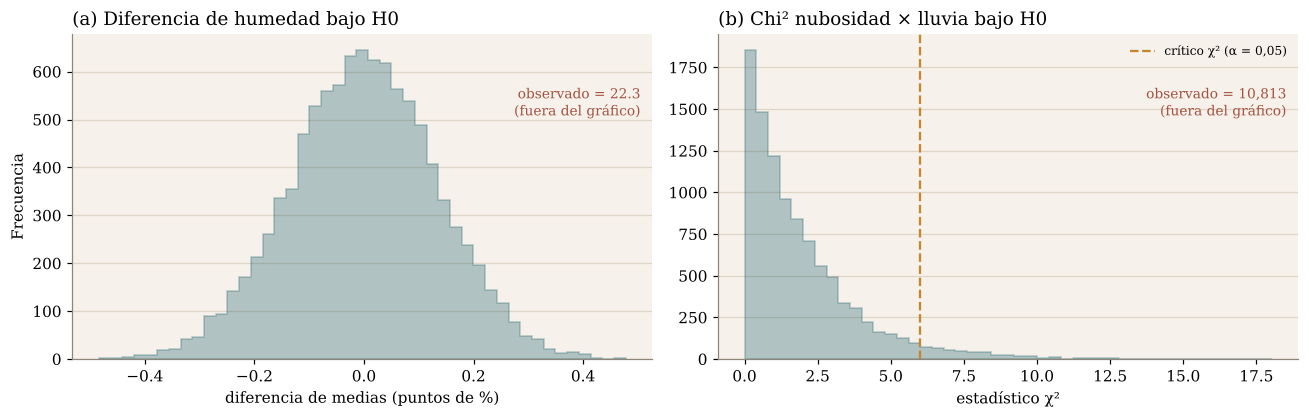

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
ax[0].hist(perm_t, bins=45, histtype='stepfilled', color=TEAL, alpha=0.35, edgecolor=TEAL)
ax[0].set_title('(a) Diferencia de humedad bajo H0')
ax[0].set_xlabel('diferencia de medias (puntos de %)'); ax[0].set_ylabel('Frecuencia')
ax[0].text(0.98, 0.75, f'observado = {obs_t:.1f}\n(fuera del gráfico)', transform=ax[0].transAxes,
           ha='right', color=TERRA, fontsize=9)
ax[1].hist(perm_chi, bins=45, histtype='stepfilled', color=TEAL, alpha=0.35, edgecolor=TEAL)
ax[1].axvline(stats.chi2.ppf(0.95, 2), color=OCHRE, ls='--', lw=1.5, label='crítico χ² (α = 0,05)')
ax[1].set_title('(b) Chi² nubosidad × lluvia bajo H0')
ax[1].set_xlabel('estadístico χ²')
ax[1].legend(frameon=False, fontsize=8)
ax[1].text(0.98, 0.75, f'observado = {obs_chi:,.0f}\n(fuera del gráfico)', transform=ax[1].transAxes,
           ha='right', color=TERRA, fontsize=9)
for a in ax:
    a.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_permutacion.png', bbox_inches='tight')
plt.show()

**Lectura.** En las dos pruebas el valor observado queda **muy lejos** de lo que produce el azar:

- **Humedad:** al mezclar las etiquetas, la diferencia de medias queda entre −0,5 y 0,5 puntos. La observada es de 22,3 puntos.
- **Nubosidad:** el χ² de las permutaciones nunca pasa de 18. El observado es 10.812,6.

Ninguna de las 10.000 permutaciones alcanza el valor real, así que el valor p de permutación es el mínimo posible con 10.000 repeticiones (1/10.001 ≈ 0,0001), es decir, p < 0,001. Coincide con los resultados paramétricos de la S1 (ambos p < 0,0001). Los dos enfoques concuerdan, y la permutación confirma que las conclusiones no dependían de los supuestos de normalidad de la *t* ni de la aproximación χ².

---
## 3. Estabilidad de correlaciones

Elegimos cinco correlaciones de la S1 (Figura 3 y pruebas de hipótesis) y les calculamos un intervalo bootstrap al 95 % con 3.000 remuestras de filas. Una correlación es **robusta** si su intervalo no cruza el 0, e **inestable** si lo cruza. Incluimos a propósito una correlación muy débil (temperatura a las 9 am con lluvia mañana) para ver qué pasa.

Nota: la correlación de horas de sol con nubosidad solo se puede calcular con las estaciones que miden las dos variables (64.892 días).

In [8]:
rng = np.random.default_rng(SEED)   # sección reproducible
B_corr = 3_000
pares = [
    ('Humidity3pm', 'y', 'Humedad 3 pm vs lluvia mañana'),
    ('Sunshine', 'Cloud3pm', 'Horas de sol vs nubosidad 3 pm'),
    ('Pressure9am', 'Pressure3pm', 'Presión 9 am vs presión 3 pm'),
    ('WindGustSpeed', 'WindSpeed3pm', 'Ráfaga vs viento 3 pm'),
    ('Temp9am', 'y', 'Temperatura 9 am vs lluvia mañana'),
]
res = []
for c1, c2, etiqueta in pares:
    s = df_obj[[c1, c2]].dropna().to_numpy(dtype=float)
    x, yy = s[:, 0], s[:, 1]
    m = len(x)
    r0 = np.corrcoef(x, yy)[0, 1]
    rs = np.empty(B_corr)
    for j in range(B_corr):
        idx = rng.integers(0, m, m)
        rs[j] = np.corrcoef(x[idx], yy[idx])[0, 1]
    lo, hi = np.percentile(rs, [2.5, 97.5])
    estado = 'inestable' if lo <= 0 <= hi else ('robusta pero débil' if max(abs(lo), abs(hi)) < 0.1 else 'robusta')
    res.append([etiqueta, r0, lo, hi, hi - lo, m, estado])

tabla_corr = pd.DataFrame(res, columns=['Par', 'r', 'IC95 inf', 'IC95 sup', 'Ancho', 'n', 'Estado']).set_index('Par')
tabla_corr.round(4)

,r,IC95 inf,IC95 sup,Ancho,n,Estado
Par,,,,,,
Humedad 3 pm vs lluvia mañana,0.4462,0.4418,0.4505,0.0087,138583,robusta
Horas de sol vs nubosidad 3 pm,-0.7043,-0.7080,-0.7007,0.0074,64892,robusta
Presión 9 am vs presión 3 pm,0.9613,0.9608,0.9618,0.0010,127989,robusta
Ráfaga vs viento 3 pm,0.6864,0.6828,0.6902,0.0074,132634,robusta
Temperatura 9 am vs lluvia mañana,-0.0257,-0.0308,-0.0208,0.0101,141289,robusta pero débil


### Figura 3 - Intervalos bootstrap de las correlaciones

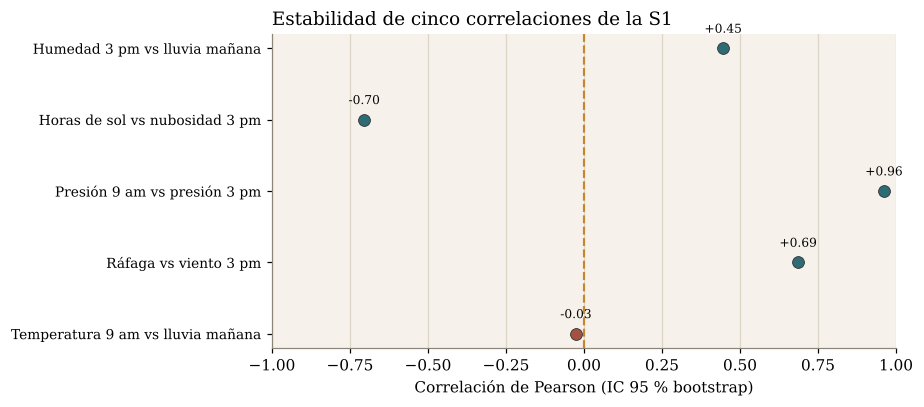

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
yy = np.arange(len(tabla_corr))[::-1]
for (etq, fila), yv in zip(tabla_corr.iterrows(), yy):
    col = TERRA if fila['Estado'] != 'robusta' else TEAL
    ax.plot([fila['IC95 inf'], fila['IC95 sup']], [yv, yv], color=col, lw=3)
    ax.scatter(fila['r'], yv, color=col, s=60, edgecolor=INK, linewidth=0.5, zorder=3)
    ax.text(fila['r'], yv + 0.22, f"{fila['r']:+.2f}", ha='center', fontsize=8)
ax.axvline(0, color=OCHRE, ls='--', lw=1.4)
ax.set_yticks(yy); ax.set_yticklabels(tabla_corr.index, fontsize=9)
ax.set_xlim(-1, 1); ax.set_xlabel('Correlación de Pearson (IC 95 % bootstrap)')
ax.set_title('Estabilidad de cinco correlaciones de la S1')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_correlaciones.png', bbox_inches='tight')
plt.show()

**Lectura.** Las cinco correlaciones son robustas: ningún intervalo cruza el 0 y todos son muy estrechos (ancho de 0,001 a 0,010), tanto que en la Figura 3 quedan tapados por el punto.

- Las dos "casi repetidas" de la S1 se confirman: presión 9 am con presión 3 pm (r = 0,96) y ráfaga con viento 3 pm (r = 0,69). Para la S3 esto significa que no conviene meter las dos variables de cada par en un mismo modelo.
- Humedad 3 pm con lluvia mañana (r = 0,45) y sol con nubosidad (r = −0,70) son relaciones fuertes y estables.
- Temperatura 9 am con lluvia mañana (r = −0,03) también sale "robusta", pero es casi cero. Con tantos datos, hasta una relación sin importancia práctica tiene un intervalo que no toca el 0. Por eso la marcamos como **robusta pero débil**: es estable, pero no sirve para predecir.

---
## 4. Simulación Monte Carlo con parámetros de la S1

**Pregunta de decisión:** si alguien tiene que planificar un mes de trabajo al aire libre (una cosecha, una obra, un evento), ¿cuántos días de lluvia debería esperar y qué tan probable es una racha de varios días seguidos de lluvia?

**Modelo:** usamos solo parámetros de la S1. La prueba *z* mostró que la lluvia "se arrastra" de un día al siguiente: si hoy llovió, mañana llueve con probabilidad 46,4 %, y si no llovió, con 15,2 %. Con esas dos probabilidades simulamos meses de 30 días, día a día (es una cadena de Markov). Cada mes simulado es un dato **sintético** que se comporta como el clima real según la S1.

Primero revisamos que el modelo sea coherente: las dos probabilidades implican una proporción de días con lluvia a largo plazo, y esa proporción debería parecerse a la que observamos en la S1.

In [10]:
# Parámetros estimados en la S1 (prueba z de dos proporciones)
d = df.dropna(subset=[TARGET, 'RainToday'])
p11 = (d.loc[d['RainToday'] == 'Yes', TARGET] == 'Yes').mean()   # P(lluvia mañana | hoy llovió)
p01 = (d.loc[d['RainToday'] == 'No', TARGET] == 'Yes').mean()    # P(lluvia mañana | hoy no llovió)
p_global = S1['p_lluvia'][0]
pi = p01 / (1 - p11 + p01)    # proporción de largo plazo que implican p11 y p01

print(f"P(lluvia mañana | hoy llovió)    = {p11:.4f}   (S1: 46,4 %)")
print(f"P(lluvia mañana | hoy no llovió) = {p01:.4f}   (S1: 15,2 %)")
print(f"Proporción de largo plazo del modelo = {pi:.4f}   vs   proporción observada en S1 = {p_global:.4f}")

P(lluvia mañana | hoy llovió)    = 0.4641   (S1: 46,4 %)
P(lluvia mañana | hoy no llovió) = 0.1519   (S1: 15,2 %)
Proporción de largo plazo del modelo = 0.2208   vs   proporción observada en S1 = 0.2242


La proporción que implica el modelo (22,1 %) es casi igual a la observada en la S1 (22,4 %), así que el modelo es coherente con los datos. Ahora simulamos 10.000 meses.

In [11]:
def simular(dias, B, rng, markov=True):
    """Simula B secuencias de 'dias' días (True = día con lluvia > 1 mm)."""
    lluvia = np.empty((B, dias), dtype=bool)
    lluvia[:, 0] = rng.random(B) < pi                 # el primer día parte con la proporción de largo plazo
    for t in range(1, dias):
        if markov:
            prob = np.where(lluvia[:, t - 1], p11, p01)   # depende de si llovió el día anterior
        else:
            prob = np.full(B, pi)                         # días independientes (misma probabilidad media)
        lluvia[:, t] = rng.random(B) < prob
    return lluvia

def racha_max(m):
    """Racha más larga de días con lluvia seguidos, por fila."""
    mejor = np.zeros(m.shape[0], dtype=int); actual = np.zeros(m.shape[0], dtype=int)
    for t in range(m.shape[1]):
        actual = np.where(m[:, t], actual + 1, 0)
        mejor = np.maximum(mejor, actual)
    return mejor

rng = np.random.default_rng(SEED)   # sección reproducible
DIAS, B_mc = 30, 10_000
mes = simular(DIAS, B_mc, rng)
dias_lluvia = mes.sum(axis=1)
rachas = racha_max(mes)

teorico = DIAS * pi
promedio_acum = np.cumsum(dias_lluvia) / np.arange(1, B_mc + 1)
ee_mc = dias_lluvia.std(ddof=1) / np.sqrt(B_mc)
lo, hi = np.percentile(dias_lluvia, [2.5, 97.5])

print(f"Días con lluvia en un mes: media = {dias_lluvia.mean():.2f}  (teórico = {teorico:.2f}), desv. est. = {dias_lluvia.std():.2f}")
print(f"Error estándar de Monte Carlo de la media = {ee_mc:.4f} días")
print(f"Intervalo del 95 % de los meses simulados = [{lo:.0f}; {hi:.0f}] días con lluvia")
print(f"P(10 o más días con lluvia) = {np.mean(dias_lluvia >= 10):.4f}")
print(f"P(al menos una racha de 3+ días seguidos con lluvia) = {np.mean(rachas >= 3):.4f}")
print(f"P(ningún día con lluvia en el mes) = {np.mean(dias_lluvia == 0):.4f}")

Días con lluvia en un mes: media = 6.62  (teórico = 6.62), desv. est. = 3.11
Error estándar de Monte Carlo de la media = 0.0311 días
Intervalo del 95 % de los meses simulados = [1; 13] días con lluvia
P(10 o más días con lluvia) = 0.1756
P(al menos una racha de 3+ días seguidos con lluvia) = 0.5570
P(ningún día con lluvia en el mes) = 0.0065


### Figura 4 - Distribución simulada y convergencia

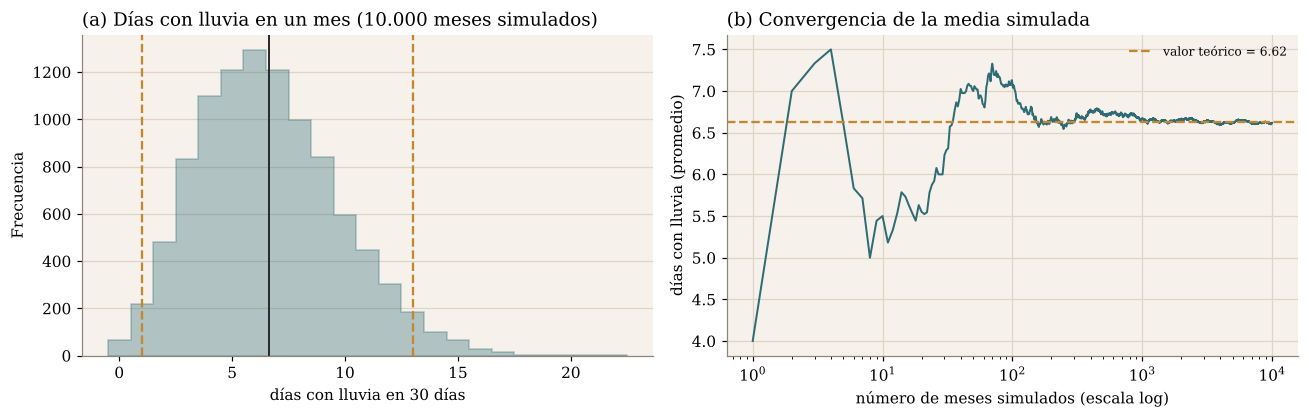

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
bins = np.arange(-0.5, dias_lluvia.max() + 1.5)
ax[0].hist(dias_lluvia, bins=bins, histtype='stepfilled', color=TEAL, alpha=0.35, edgecolor=TEAL)
for v in (lo, hi):
    ax[0].axvline(v, color=OCHRE, ls='--', lw=1.5)
ax[0].axvline(teorico, color=INK, lw=1.3)
ax[0].set_title('(a) Días con lluvia en un mes (10.000 meses simulados)')
ax[0].set_xlabel('días con lluvia en 30 días'); ax[0].set_ylabel('Frecuencia')
ax[0].grid(axis='x', visible=False)
ax[1].plot(np.arange(1, B_mc + 1), promedio_acum, color=TEAL, lw=1.3)
ax[1].axhline(teorico, color=OCHRE, ls='--', lw=1.5, label=f'valor teórico = {teorico:.2f}')
ax[1].set_xscale('log')
ax[1].set_title('(b) Convergencia de la media simulada')
ax[1].set_xlabel('número de meses simulados (escala log)'); ax[1].set_ylabel('días con lluvia (promedio)')
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_montecarlo.png', bbox_inches='tight')
plt.show()

**Lectura.**

- **Coherencia y convergencia:** el promedio simulado es 6,62 días de lluvia por mes, igual al valor teórico (30 × 0,221). En la Figura 4b el promedio se estabiliza después de unos mil meses y, con 10.000, el error estándar de Monte Carlo es de solo 0,03 días. O sea, 10.000 iteraciones son suficientes.
- **Para planificar:** un mes típico tiene entre 1 y 13 días con lluvia (95 % de los meses simulados). Hay un 17,6 % de probabilidad de tener 10 o más días con lluvia, y un **55,7 %** de que en el mes haya al menos una racha de 3 o más días seguidos con lluvia. Casi nunca hay un mes completo sin lluvia (0,7 %).

### 4.1 Escenarios: horizonte de planificación y supuesto de persistencia

Repetimos la simulación para 7, 30 y 90 días, y la comparamos con un modelo que **ignora la persistencia** (cada día llueve con la misma probabilidad, sin importar el día anterior). Los dos modelos tienen la misma probabilidad media; lo único que cambia es si un día depende del anterior.

In [13]:
filas = []
dist_mes = {}
for modelo, es_markov in [('Con persistencia (S1)', True), ('Días independientes', False)]:
    for dias in [7, 30, 90]:
        rng = np.random.default_rng(SEED)            # misma semilla en cada escenario
        sim = simular(dias, B_mc, rng, markov=es_markov)
        n_ll = sim.sum(axis=1)
        if dias == 30:
            dist_mes[modelo] = n_ll
        r = racha_max(sim)
        lo_e, hi_e = np.percentile(n_ll, [2.5, 97.5])
        filas.append([modelo, dias, n_ll.mean(), n_ll.std(), f"[{lo_e:.0f}; {hi_e:.0f}]", np.mean(r >= 3)])

tabla_esc = pd.DataFrame(filas, columns=['Modelo', 'Días', 'Media días lluvia', 'Desv. est.',
                                         'IC 95 %', 'P(racha ≥ 3)']).set_index(['Modelo', 'Días'])
tabla_esc.round(3)

Media días lluvia  Desv. est.   IC 95 %  \
Modelo                Días                                            
Con persistencia (S1) 7                 1.546       1.443    [0; 5]   
                      30                6.617       3.112   [1; 13]   
                      90               19.916       5.410  [10; 31]   
Días independientes   7                 1.541       1.101    [0; 4]   
                      30                6.623       2.275   [2; 11]   
                      90               19.865       3.929  [12; 28]   

                            P(racha ≥ 3)  
Modelo                Días                
Con persistencia (S1) 7            0.150  
                      30           0.557  
                      90           0.919  
Días independientes   7            0.039  
                      30           0.212  
                      90           0.536

### Figura 5 - Efecto de la persistencia en un mes

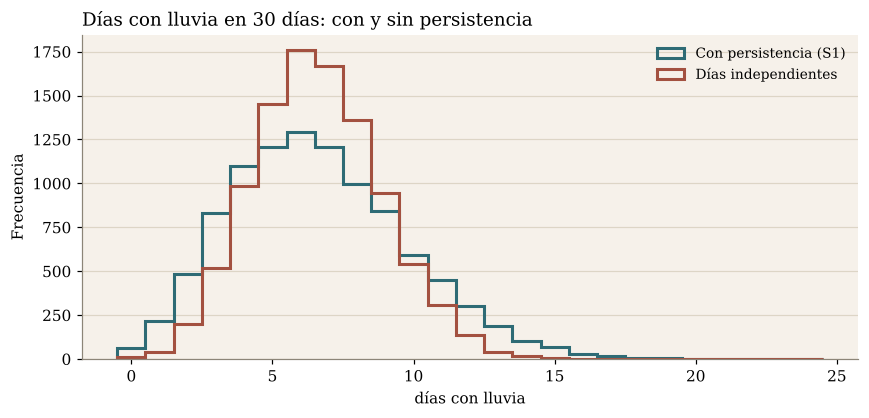

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.9))
bins = np.arange(-0.5, 25.5)
for modelo, col in [('Con persistencia (S1)', TEAL), ('Días independientes', TERRA)]:
    ax.hist(dist_mes[modelo], bins=bins, histtype='step', lw=2, color=col, label=modelo)
ax.set_title('Días con lluvia en 30 días: con y sin persistencia')
ax.set_xlabel('días con lluvia'); ax.set_ylabel('Frecuencia')
ax.legend(frameon=False, fontsize=9)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_escenarios.png', bbox_inches='tight')
plt.show()

**Lectura.** El promedio de días con lluvia es el mismo en los dos modelos (6,6 en 30 días), pero **el riesgo no**:

- Con persistencia los meses son más variables (desviación de 3,1 días contra 2,3) y el rango del 95 % se abre de [2; 11] a [1; 13] días.
- La probabilidad de una racha de 3 o más días seguidos con lluvia en un mes sube de **21 % a 56 %**. En 90 días, de 54 % a 92 %.

Para la decisión, esto significa que si se planifica suponiendo que los días son independientes, se subestima bastante el riesgo de varios días de lluvia seguidos, que es justo lo que más complica un trabajo al aire libre. Además, a horizontes más largos la cantidad de días con lluvia es más predecible en proporción (en 7 días puede ir de 0 a 5, pero en 90 se concentra entre 10 y 31).

---
## 5. Análisis de robustez

Revisamos qué tan sensibles son los resultados de la S1 a los valores extremos y al supuesto de que los días son independientes.

### 5.1 Media de la lluvia diaria: valores extremos y jackknife

In [15]:
# a) Media de la lluvia diaria: estimadores robustos y jackknife
r = df['Rainfall'].dropna().to_numpy(dtype=float)
n_r = len(r)
jack = (r.sum() - r) / (n_r - 1)
se_jack = np.sqrt((n_r - 1) / n_r * ((jack - jack.mean()) ** 2).sum())
influencia = (n_r - 1) * (jack.mean() - jack)       # cuánto mueve cada día a la media
robustez = pd.Series({
    'Media completa': r.mean(),
    'Media recortada al 5 %': stats.trim_mean(r, 0.05),
    'Media sin el 1 % superior': r[r <= np.percentile(r, 99)].mean(),
    'Mediana': np.median(r),
}, name='mm').round(3)
print(f"Error estándar jackknife de la media = {se_jack:.4f} mm  (clásico = {r.std(ddof=1)/np.sqrt(n_r):.4f})")
print(f"Día más influyente: {r[np.argmax(np.abs(influencia))]:.0f} mm")
robustez.to_frame()

Error estándar jackknife de la media = 0.0225 mm  (clásico = 0.0225)
Día más influyente: 371 mm


,mm
Media completa,2.361
Media recortada al 5 %,0.975
Media sin el 1 % superior,1.737
Mediana,0.000


**Lectura.** La media de la lluvia (2,36 mm) es muy sensible a los días extremos: baja a 1,74 mm si se quita solo el 1 % de días con más lluvia, y a 0,98 mm con la media recortada al 5 %. La mediana es 0 mm. El jackknife confirma que el **error estándar** de la media está bien estimado (0,0225 mm, igual al clásico), así que el intervalo de la S1 es correcto, pero la media **no representa un día típico**. Para describir la lluvia conviene usar la mediana o la proporción de días con lluvia. El día más influyente es el de 371 mm.

### 5.2 Supuesto de independencia: bootstrap por ciudad

En la S1 advertimos que los datos son días seguidos de las mismas 49 ciudades, así que no son independientes. Para medir cuánto importa, repetimos el bootstrap de la proporción de lluvia, pero remuestreando **ciudades completas** en vez de días sueltos.

In [16]:
# b) Supuesto de independencia: bootstrap por ciudad (se remuestrean ciudades completas)
rng = np.random.default_rng(SEED)
por_ciudad = df_obj.groupby('Location')['y'].agg(['sum', 'count'])
k_c, n_c = por_ciudad['sum'].to_numpy(), por_ciudad['count'].to_numpy()
G = len(k_c)
reps_c = np.empty(B)
for j in range(B):
    i = rng.integers(0, G, G)
    reps_c[j] = k_c[i].sum() / n_c[i].sum()
lo_c, hi_c = np.percentile(reps_c, [2.5, 97.5])
lo_d, hi_d = boot['p_lluvia']['percentil']
print(f"Proporción de lluvia mañana = {S1['p_lluvia'][0]:.4f}")
print(f"  IC bootstrap por días (supone días independientes): [{lo_d:.4f}; {hi_d:.4f}]  ancho = {hi_d-lo_d:.4f}")
print(f"  IC bootstrap por ciudad ({G} ciudades)            : [{lo_c:.4f}; {hi_c:.4f}]  ancho = {hi_c-lo_c:.4f}")
print(f"  El intervalo se ensancha {(hi_c-lo_c)/(hi_d-lo_d):.0f} veces")
tasa_ciudad = (por_ciudad['sum'] / por_ciudad['count'] * 100).sort_values()
print(f"Rango entre ciudades: {tasa_ciudad.min():.1f} % ({tasa_ciudad.idxmin()}) a {tasa_ciudad.max():.1f} % ({tasa_ciudad.idxmax()})")

Proporción de lluvia mañana = 0.2242
  IC bootstrap por días (supone días independientes): [0.2220; 0.2263]  ancho = 0.0043
  IC bootstrap por ciudad (49 ciudades)            : [0.2055; 0.2420]  ancho = 0.0365
  El intervalo se ensancha 8 veces
Rango entre ciudades: 6.8 % (Woomera) a 36.5 % (Portland)


**Lectura.** Este es el hallazgo más importante de la sección. Si se toman los días como independientes, el intervalo de la proporción de lluvia es [22,20 %; 22,63 %]. Si se remuestrean ciudades, pasa a [20,55 %; 24,20 %], unas **8 veces más ancho**. La razón es que la lluvia cambia mucho entre ciudades: va de 6,8 % en Woomera (desierto) a 36,5 % en Portland. Entonces el 22,4 % es un promedio confiable para el conjunto de estaciones, pero la incertidumbre real es mayor que la que mostraba el intervalo clásico, y no conviene aplicar ese número a una ciudad en particular.

### 5.3 La diferencia de humedad, ciudad por ciudad

In [17]:
# c) La diferencia de humedad, ciudad por ciudad y con medianas
dif_ciudad = (df_obj.dropna(subset=['Humidity3pm'])
              .groupby('Location')
              .apply(lambda g: g.loc[g['y'] == 1, 'Humidity3pm'].mean() - g.loc[g['y'] == 0, 'Humidity3pm'].mean()))
dif_mediana = h.loc[h['y'] == 1, 'Humidity3pm'].median() - h.loc[h['y'] == 0, 'Humidity3pm'].median()
print(f"Diferencia de medias (todas las ciudades) = {obs_t:.1f} puntos;  diferencia de medianas = {dif_mediana:.1f}")
print(f"Ciudades con humedad más alta antes de lluvia: {(dif_ciudad > 0).sum()} de {len(dif_ciudad)}")
print(f"Rango de la diferencia por ciudad: {dif_ciudad.min():.1f} a {dif_ciudad.max():.1f} puntos")

Diferencia de medias (todas las ciudades) = 22.3 puntos;  diferencia de medianas = 23.0
Ciudades con humedad más alta antes de lluvia: 49 de 49
Rango de la diferencia por ciudad: 6.6 a 33.3 puntos


**Lectura.** La diferencia de humedad entre días previos a lluvia y días previos a no lluvia es muy robusta: con medianas da casi lo mismo que con medias (23,0 vs 22,3 puntos) y se cumple en **las 49 ciudades**, aunque con distinta fuerza (de 6,6 a 33,3 puntos). No depende de unas pocas estaciones ni de valores extremos.

**Resumen de robustez:** son confiables la diferencia de humedad, la asociación con la nubosidad (en las estaciones que la miden), las correlaciones y la persistencia de la lluvia. Requieren cautela la media de la lluvia (sensible a extremos) y la precisión de la proporción global (los intervalos clásicos subestiman la incertidumbre porque los días de una misma ciudad no son independientes).

---
## 6. Reporte de resultados validados para la Sumativa 3

Guardamos este resumen en `data/processed/resultados_validados_f2.csv` para usarlo en la S3.

In [18]:
validados = pd.DataFrame([
    ['Temperatura máxima media', 'Clásico, percentil y BCa coinciden', 'Robusto'],
    ['Humedad media 3 pm', 'Clásico, percentil y BCa coinciden', 'Robusto'],
    ['Lluvia diaria media', 'Intervalos coinciden, pero la media es muy sensible a días extremos', 'Cautela: preferir mediana'],
    ['Proporción de lluvia mañana', 'IC por días muy estrecho; por ciudad mucho más ancho', 'Robusto como promedio; varía por ciudad'],
    ['Welch humedad (S1)', 'Permutación p < 0,001; se cumple en todas las ciudades', 'Robusto'],
    ['Chi² nubosidad (S1)', 'Permutación p < 0,001; ~40 % faltante no al azar', 'Robusto en estaciones que miden nubes'],
    ['Correlaciones de la S1', 'IC bootstrap estrechos, ninguno cruza 0', 'Robustas (Temp 9 am muy débil)'],
    ['Persistencia de la lluvia (46,4 % vs 15,2 %)', 'Monte Carlo reproduce la proporción observada', 'Robusto'],
], columns=['Resultado', 'Validación en F2', 'Estado'])
validados.to_csv(PROCESADOS / 'resultados_validados_f2.csv', index=False, encoding='utf-8')
print("Guardado en data/processed/resultados_validados_f2.csv")
validados

Guardado en data/processed/resultados_validados_f2.csv


,Resultado,Validación en F2,Estado
0,Temperatura máxima media,"Clásico, percentil y BCa coinciden",Robusto
1,Humedad media 3 pm,"Clásico, percentil y BCa coinciden",Robusto
2,Lluvia diaria media,"Intervalos coinciden, pero la media es muy sen...",Cautela: preferir mediana
3,Proporción de lluvia mañana,IC por días muy estrecho; por ciudad mucho más...,Robusto como promedio; varía por ciudad
4,Welch humedad (S1),"Permutación p < 0,001; se cumple en todas las ...",Robusto
5,Chi² nubosidad (S1),"Permutación p < 0,001; ~40 % faltante no al azar",Robusto en estaciones que miden nubes
6,Correlaciones de la S1,"IC bootstrap estrechos, ninguno cruza 0",Robustas (Temp 9 am muy débil)
7,"Persistencia de la lluvia (46,4 % vs 15,2 %)",Monte Carlo reproduce la proporción observada,Robusto


**Recomendaciones para la Sumativa 3:**

- Usar como predictores las variables con relaciones robustas y fuertes: humedad a las 3 pm, nubosidad, lluvia de hoy y presión.
- No poner juntas en un modelo las variables casi repetidas (presión 9 am y 3 pm; ráfaga y viento 3 pm; temperaturas máxima y 3 pm).
- Para la lluvia, usar la mediana o una variable de "llovió / no llovió" en vez de la media, o recortar los extremos.
- `Sunshine` y `Cloud3pm` son de las variables más útiles, pero les falta cerca del 40-48 % de los datos y no al azar (hay estaciones que no las miden). Hay que decidir cómo imputarlas (por ejemplo, por regresión).
- Tener en cuenta que los días de una misma ciudad no son independientes, y que la probabilidad de lluvia varía mucho entre ciudades: conviene considerar la ciudad o la zona en el modelo y validar separando por ciudad o por tiempo.
- La variable objetivo está desbalanceada (22,4 %): cualquier modelo debe superar el 78 % de acierto de decir siempre "no llueve".